# PetroTwin fuel-market EDA

This notebook covers M2 tasks T10 (exploratory analysis) and T11 (target/feature relationships). It reads the latest accepted processed snapshot through `data/processed/current.json`, records the run ID, and keeps the event-level grain. It does not rewrite source or processed data.

The accepted dataset is for research/model development. See `docs/DATA_INTERFACE.md` and `reports/data-foundation-acceptance.md` for the data contract and known source limitations.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the checkout root whether Jupyter starts in the repo root or this notebook's folder.
candidates = [Path.cwd(), *Path.cwd().parents]
repo_root = next((p for p in candidates if (p / 'data/processed/current.json').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Run this notebook from within a PetroTwin checkout containing data/processed/current.json')

pointer = json.loads((repo_root / 'data/processed/current.json').read_text(encoding='utf-8'))
run_id = pointer['run_id']
run_dir = repo_root / 'data/processed' / pointer['path']
panel = pd.read_csv(run_dir / 'fuel_market_panel.csv')
market = pd.read_csv(run_dir / 'market_observation.csv')
panel['effective_at_local'] = pd.to_datetime(panel['effective_at_local'], utc=True).dt.tz_convert('Asia/Ho_Chi_Minh')
panel['event_date'] = panel['effective_at_local'].dt.date
for col in ['brent_observation_date', 'fx_observation_date']:
    panel[col] = pd.to_datetime(panel[col], errors='coerce')

print(f'Snapshot: {run_id} | Schema: {pointer["schema_version"]} | Panel rows: {len(panel):,}')
print(f'Fuel events: {panel.event_date.min()} through {panel.event_date.max()} | {panel.event_date.nunique():,} distinct event dates')
panel.head(3)

Snapshot: 28b22922e761cb08a8d8 | Schema: petrotwin-data-v3 | Panel rows: 1,390
Fuel events: 2018-08-22 through 2026-10-22 | 310 distinct event dates


,product_id,source_product_name,source_record_date,effective_at_local,price_value,price_change_value,stabilization_fund_subsidy,stabilization_fund_subsidy_amount,stabilization_fund_subsidy_unit,stabilization_fund_source_url,...,brent_age_days,brent_usd_per_barrel_unit,fx_source_id,fx_snapshot_id,fx_observation_date,usd_vnd_rate,fx_age_days,usd_vnd_rate_unit,schema_version,event_date
0,diesel_0005s_iv,"Dầu DO 0,005S-IV",2018-08-22,2018-08-22 00:00:00+07:00,17730,NaN,NaN,NaN,VND/liter,NaN,...,NaN,USD/bbl,sbv_reference_via_algolab,NaN,NaT,NaN,NaN,VND/USD,petrotwin-data-v3,2018-08-22
1,diesel_005s_ii,"Dầu DO 0,05S-II",2018-08-22,2018-08-22 00:00:00+07:00,17680,NaN,NaN,NaN,VND/liter,NaN,...,NaN,USD/bbl,sbv_reference_via_algolab,NaN,NaT,NaN,NaN,VND/USD,petrotwin-data-v3,2018-08-22
2,kerosene_ko,Dầu KO,2018-08-22,2018-08-22 00:00:00+07:00,16260,NaN,NaN,NaN,VND/liter,NaN,...,NaN,USD/bbl,sbv_reference_via_algolab,NaN,NaT,NaN,NaN,VND/USD,petrotwin-data-v3,2018-08-22


## T10 — coverage, price behavior, and calendar pattern

Fuel prices are irregular adjustment events. The notebook does not expand them to daily rows or fill gaps. Product IDs stay separate because grades have different histories and are not interchangeable.

In [2]:
def median_interval_days(dates):
    dates = pd.Series(pd.to_datetime(dates).dropna().sort_values().unique())
    gaps = dates.diff().dt.days.dropna()
    return gaps.median() if not gaps.empty else np.nan

product_summary = (panel.groupby('product_id', sort=True)
    .apply(lambda g: pd.Series({
        'events': len(g),
        'first_event': g['event_date'].min(),
        'last_event': g['event_date'].max(),
        'median_gap_days': median_interval_days(g['event_date']),
        'price_min_vnd_liter': g['price_value'].min(),
        'price_median_vnd_liter': g['price_value'].median(),
        'price_max_vnd_liter': g['price_value'].max(),
        'reported_change_missing_pct': 100 * g['price_change_value'].isna().mean(),
        'brent_missing_pct': 100 * g['brent_usd_per_barrel'].isna().mean(),
        'fx_missing_pct': 100 * g['usd_vnd_rate'].isna().mean(),
        'fund_verified_pct': 100 * g['stabilization_fund_subsidy'].notna().mean(),
    })))
product_summary

,events,first_event,last_event,median_gap_days,price_min_vnd_liter,price_median_vnd_liter,price_max_vnd_liter,reported_change_missing_pct,brent_missing_pct,fx_missing_pct,fund_verified_pct
product_id,,,,,,,,,,,
diesel_0001s_v,119,2024-09-26,2026-10-22,7.0,17430,19360.0,44980,0.000000,0.000000,0.000000,64.705882
diesel_0005s_iv,10,2018-08-22,2019-01-01,15.0,14950,17920.0,18660,10.000000,10.000000,10.000000,0.000000
diesel_005s_ii,310,2018-08-22,2026-10-22,7.0,9850,18980.0,44780,0.322581,0.322581,0.322581,39.354839
fuel_oil_35s,1,2024-05-30,2024-05-30,NaN,17530,17530.0,17530,0.000000,0.000000,0.000000,0.000000
gasoline_e10_ron95_iii,74,2025-07-31,2026-10-22,7.0,18460,21315.0,31420,0.000000,0.000000,0.000000,21.621622
gasoline_e5_ron92_ii,310,2018-08-22,2026-10-22,7.0,10940,20500.0,31300,0.322581,0.322581,0.322581,40.322581
gasoline_ron95_iii,287,2018-08-22,2026-05-28,8.0,11630,21230.0,33840,0.348432,0.348432,0.348432,40.418118
gasoline_ron95_iv,10,2018-08-22,2019-01-01,15.0,17800,21315.0,22540,10.000000,10.000000,10.000000,0.000000
kerosene_ko,269,2018-08-22,2026-03-07,9.0,7880,18620.0,35090,0.371747,0.371747,0.371747,40.520446


In [3]:
change_counts = pd.Series({
    'increase': int(panel['price_change_value'].gt(0).sum()),
    'decrease': int(panel['price_change_value'].lt(0).sum()),
    'no change': int(panel['price_change_value'].eq(0).sum()),
    'missing': int(panel['price_change_value'].isna().sum()),
}, name='fuel events')
annual_dates = (panel[['event_date']].drop_duplicates()
    .assign(year=lambda d: pd.to_datetime(d['event_date']).dt.year)
    .groupby('year').size().rename('distinct adjustment dates'))
fund_counts = panel['stabilization_fund_subsidy'].value_counts(dropna=False).rename(index={0.0: 'verified no spending', 1.0: 'verified spending', np.nan: 'unverified'})
display(change_counts.to_frame(), annual_dates.to_frame(), fund_counts.to_frame())

,fuel events
increase,666
decrease,653
no change,65
missing,6


,distinct adjustment dates
year,
2018,9
2019,25
2020,24
2021,24
2022,34
2023,37
2024,52
2025,54
2026,51


,count
stabilization_fund_subsidy,
NaN,825
verified no spending,435
verified spending,130


,rows,first_observation,last_observation,explicit_missing_rows
series_id,,,,
brent_dated_usd_bbl,2128,2018-08-22,2026-10-20,62
usd_vnd_sbv_reference,2400,2018-08-22,2026-10-22,0


,"mean distinct adjustment dates, 2019-2025"
month,
1,3.000000
2,2.714286
3,2.857143
4,2.857143
5,3.142857
6,2.857143
7,3.142857
8,3.142857
9,2.714286


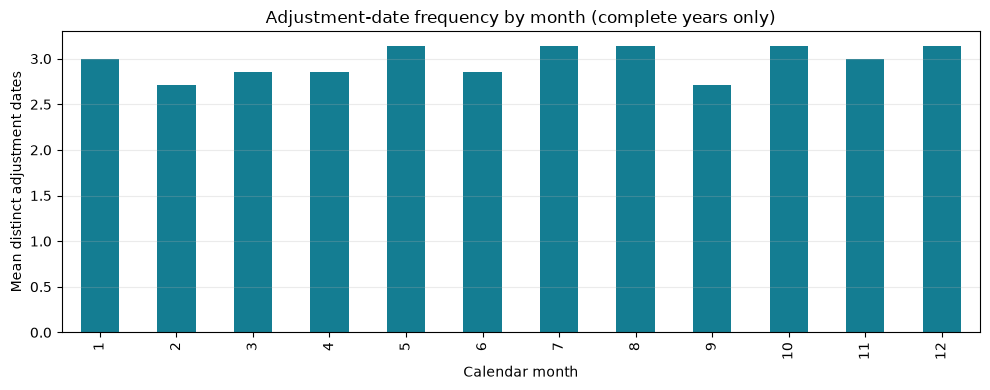

In [4]:
market['observation_date'] = pd.to_datetime(market['observation_date'], errors='coerce')
market_summary = (market.groupby('series_id', sort=True)
    .apply(lambda g: pd.Series({
        'rows': len(g),
        'first_observation': g['observation_date'].min().date(),
        'last_observation': g['observation_date'].max().date(),
        'explicit_missing_rows': int(g['observation_status'].eq('missing').sum()),
    })))

# Use complete calendar years for the month-of-year comparison; 2018 and 2026 are partial.
all_dates = panel[['event_date']].drop_duplicates().copy()
all_dates['date'] = pd.to_datetime(all_dates['event_date'])
complete_years = all_dates.loc[all_dates['date'].dt.year.between(2019, 2025)].copy()
complete_years['year'] = complete_years['date'].dt.year
complete_years['month'] = complete_years['date'].dt.month
monthly_event_days = (complete_years.groupby(['year', 'month']).size()
    .unstack('month').reindex(columns=range(1, 13), fill_value=0))
monthly_mean = monthly_event_days.mean().rename('mean distinct adjustment dates, 2019-2025')
display(market_summary, monthly_mean.to_frame())

ax = monthly_mean.plot(kind='bar', figsize=(10, 4), color='#147d92')
ax.set_xlabel('Calendar month')
ax.set_ylabel('Mean distinct adjustment dates')
ax.set_title('Adjustment-date frequency by month (complete years only)')
ax.grid(axis='y', alpha=.25)
plt.tight_layout()
plt.show()

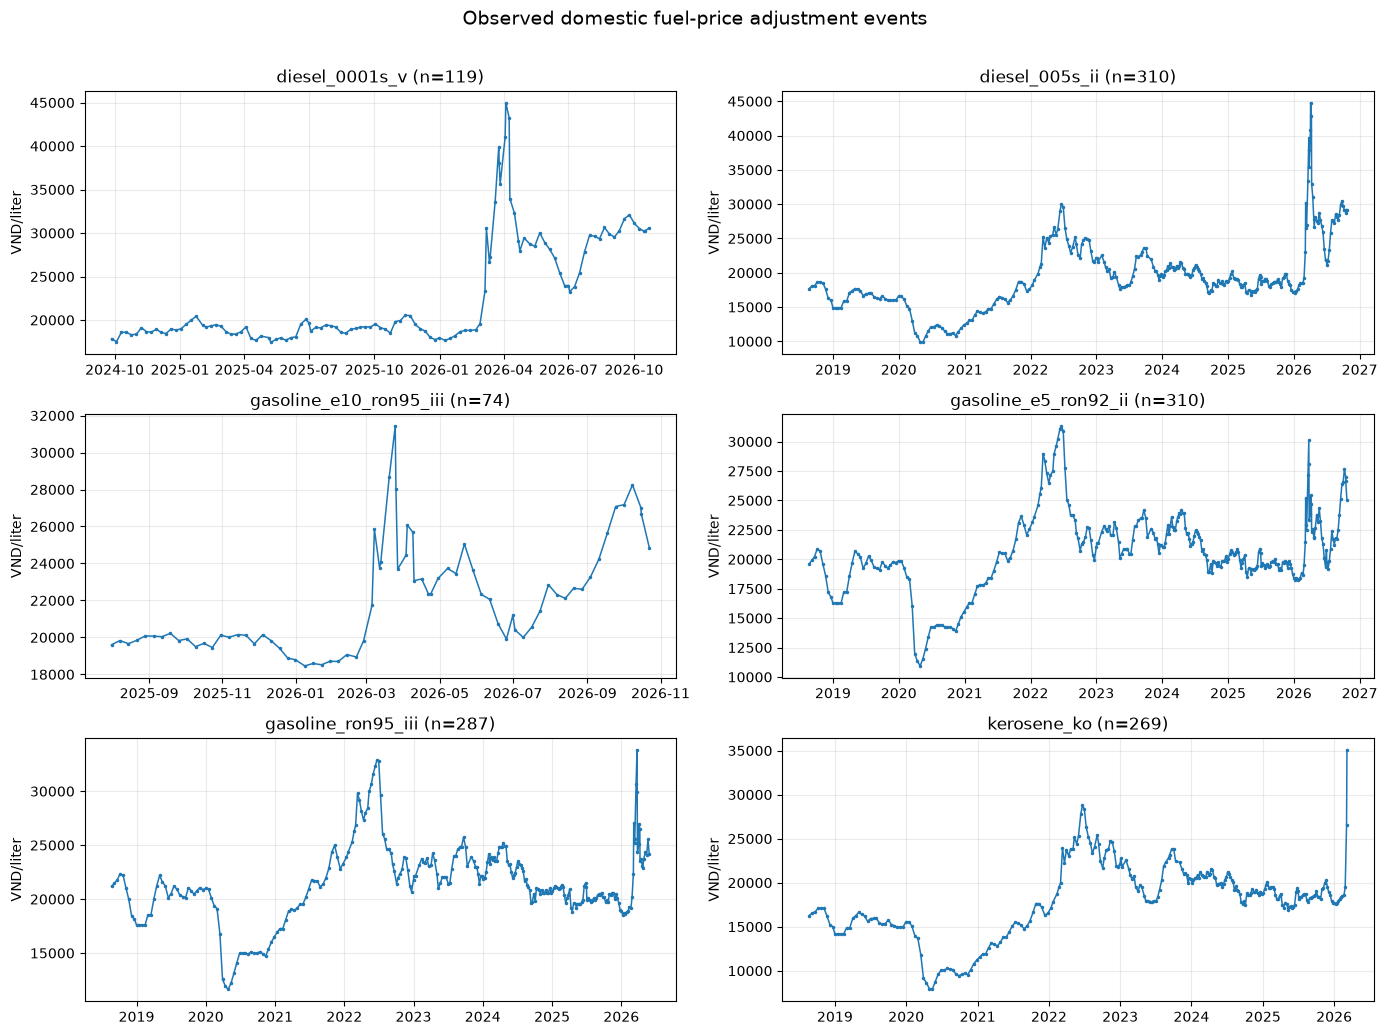

In [5]:
# One panel per product with at least 50 observations; sparse products are excluded from this comparison.
plot_products = product_summary.index[product_summary['events'] >= 50].tolist()
ncols = 2
nrows = int(np.ceil(len(plot_products) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.4 * nrows), squeeze=False)
for ax, product_id in zip(axes.flat, plot_products):
    g = panel.loc[panel['product_id'].eq(product_id)].sort_values('effective_at_local')
    ax.plot(g['effective_at_local'], g['price_value'], marker='.', linewidth=1.1, markersize=3)
    ax.set_title(f'{product_id} (n={len(g)})')
    ax.set_ylabel('VND/liter')
    ax.grid(alpha=.25)
for ax in axes.flat[len(plot_products):]:
    ax.set_visible(False)
fig.suptitle('Observed domestic fuel-price adjustment events', y=1.01, fontsize=14)
fig.tight_layout()
plt.show()

## T11 — target/feature relationships and point-in-time cautions

A pooled correlation of raw price levels can mostly reflect time trends and different product histories. The table below therefore reports within-product Spearman associations between the source-reported price change and changes in the latest strictly prior Brent/FX values attached to successive fuel events. Treat these as screening evidence, not causal effects or proof of predictive value. Rows with fewer than 50 fuel events are shown in the product coverage table but omitted from correlation screening.

In [6]:
association_rows = []
for product_id, g in panel.sort_values('effective_at_local').groupby('product_id'):
    if len(g) < 50:
        continue
    delta = pd.DataFrame({
        'reported_price_change': g['price_change_value'].to_numpy(),
        'brent_delta': g['brent_usd_per_barrel'].diff().to_numpy(),
        'fx_delta': g['usd_vnd_rate'].diff().to_numpy(),
    })
    for feature in ['brent_delta', 'fx_delta']:
        pair = delta[['reported_price_change', feature]].dropna()
        rho = pair['reported_price_change'].corr(pair[feature], method='spearman') if len(pair) >= 3 else np.nan
        association_rows.append({'product_id': product_id, 'feature_change': feature, 'n_events': len(pair), 'spearman_rho': rho})
associations = pd.DataFrame(association_rows)
associations

,product_id,feature_change,n_events,spearman_rho
0,diesel_0001s_v,brent_delta,118,0.345717
1,diesel_0001s_v,fx_delta,118,0.107591
2,diesel_005s_ii,brent_delta,308,0.486118
3,diesel_005s_ii,fx_delta,308,0.061536
4,gasoline_e10_ron95_iii,brent_delta,73,0.296185
5,gasoline_e10_ron95_iii,fx_delta,73,0.157846
6,gasoline_e5_ron92_ii,brent_delta,308,0.493673
7,gasoline_e5_ron92_ii,fx_delta,308,0.068541
8,gasoline_ron95_iii,brent_delta,285,0.507376
9,gasoline_ron95_iii,fx_delta,285,0.053874


### Interpretation and handoff

- Keep the target at fuel-adjustment-event grain unless M3 and the group explicitly choose a different forecast horizon/target. Do not invent daily targets from event prices.
- Use product-specific histories; thin series (fewer than 50 events) are descriptive only at this stage. E10 has a short history, while FO coverage is not representative because zero-price rows are quarantined.
- `price_change_value` can be NULL, and fund annotations are verified for only a subset. Missing values are not zero.
- Brent/FX panel dates are strictly before each event date, but the project has not yet defined a forecast origin or source publication-time lag. M3 should set the as-of cutoff before treating these joins as leakage-safe features.
- Correlations do not establish causal impact. Regulation, taxes, stabilization policy, and discrete pricing decisions may mediate the observed relationships.

The current data limitations (secondary FX attribution, unverified source reuse terms, and unresolved PVOIL FO zero-price semantics) remain documented in the accepted data-foundation report.